# Disclaimer

Part of this lecture has been adapted from Jan Kirenz's tutorial titled Social Network analysis with Python (https://www.kirenz.com/post/2019-08-13-network_analysis/), which is released under a Creative Commons Attribution-ShareAlike 4.0 International License.



# Social network anlaysis




# Lesson intended learning outcomes

At the end of this lesson, you should be able to:
1. **Explain** the meaning of social network analysis.
2. **Define** a social network in Python and **conduct** a simple social network analysis to it.




# Part 0: What is social network anlaysis

Social network analysis refers to the **study of the relationships, interactions and communications among a group of individual entities**. Such "entities" could be users (people) in a social network, but could also be organizations, computers, webpages (as in the case of **link analysis**), and any other entities that may connect and interact with one another in different ways.

A social network is represented in a data structure called "**graph**". The following figure shows an example of a graph, which depicts the connections among employees in a company:

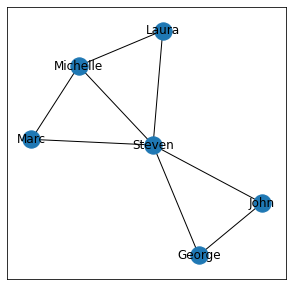

Each graph consists of:
- **Nodes**: The individuals whose network we are building (i.e., the blue dots in the figure)
- **Edges**: The connection between the nodes (i.e., the lines connecting the dots in the figure). It represents a relationship between the nodes of the network.

In the graph above, therefore, Steven is connected to all the other users, while John is only connected to two users (Steven and George). Social network analysis would reveal how the nodes connect to one another, as well as how important the nodes are.

# Part 1: Defining a social network in Python

We might use the module ```NetworkX``` to define and analyze a social network in Python. This Python package allows for the creation, manipulation, and study of the structure, dynamics, and functions of complex networks.

To use ```networkx```, we need to install it first:

In [ ]:
! pip install networkx

As always, we import networkx and other required libraries:

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
#import warnings; warnings.simplefilter('ignore')

## Symmetric (undirected) networks

Here we take a closer look at the network of employees as an example. This network represents group of employees working together in a company. This is called a symmetric network because the relationship “working together” is a symmetric relationship:

> If A is working together with B, then B is also working together with A.

To define such a symmetric network, we simply add edge between pairs of nodes. Note that the order in which the nodes (names) appear in the function does not matter, because the edges are undirected.

Number of nodes: 6
Number of edges: 8


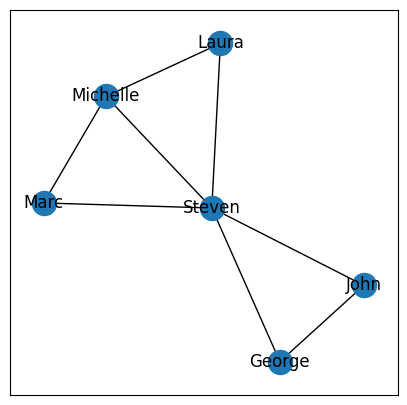

In [ ]:
# Create the graph object
G_symmetric = nx.Graph()  # Graph() will create an undirected graph

# Define the edges and nodes
G_symmetric.add_edge('Steven',  'Laura')
G_symmetric.add_edge('Steven',  'Marc')
G_symmetric.add_edge('Steven',  'John')
G_symmetric.add_edge('Steven',  'Michelle')
G_symmetric.add_edge('Laura',   'Michelle')
G_symmetric.add_edge('Michelle', 'Marc')
G_symmetric.add_edge('George',   'John')
G_symmetric.add_edge('George',   'Steven')

# Show basic info and visualize (Fixed)
print(f"Number of nodes: {G_symmetric.number_of_nodes()}")
print(f"Number of edges: {G_symmetric.number_of_edges()}")

plt.figure(figsize=(5, 5))
nx.spring_layout(G_symmetric)
nx.draw_networkx(G_symmetric)
plt.show()

## Asymmetric (directed) networks

In contrast, an asymmetric network is one that is directed, i.e.,

> Even if A points to B, B does not (necessarily) point to A.

In real life context:

> A may be a follower of B on IG, but B needs not be a follower of A.

> Webpage A links to anther webpage B, but B does not necessarily link to A.

> A has sent a message to B, but B needs not have sent a message to A.

> A has a crush on B, but B needs not have a crush on A. (!)

To define a relationship in an asymmetric network, one should use ```DiGraph()``` instead of ```Graph()``` to create the graph object. When defining the edges, one should specify the direction clearly.

E.g., if ```G_asymmetric``` is defined as a ```DiGraph``` object, then

```python
G_asymmetric.add_edge('A','B')
```

would define an edge from A to B but not vice versa. If you want an edge from B to A as well, you need to define another edge as follows:

```python
G_asymmetric.add_edge('B','A')
```


Number of nodes: 5
Number of edges: 6


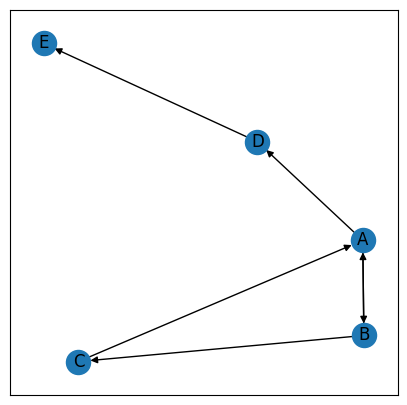

In [ ]:
# Create the graph object
G_asymmetric = nx.DiGraph()  # Note: DiGraph instead of just Graph

# Define the edges and nodes
G_asymmetric.add_edge('A', 'B')  # A->B
G_asymmetric.add_edge('B', 'A')  # B->A (not the same as above)
G_asymmetric.add_edge('B', 'C')
G_asymmetric.add_edge('A', 'D')
G_asymmetric.add_edge('C', 'A')
G_asymmetric.add_edge('D', 'E')

# Show info and visualize (Fixed)
print(f"Number of nodes: {G_asymmetric.number_of_nodes()}")
print(f"Number of edges: {G_asymmetric.number_of_edges()}")

plt.figure(figsize=(5, 5))
nx.spring_layout(G_asymmetric)
nx.draw_networkx(G_asymmetric)
plt.show()

Note that there are 6 edges in the graph above although there are only five lines. This is because the line bewteen A and B is a double arrow, which is counted as two edges.

## Networks with weights

Till now we have had networks without weights, but it is possible that networks are made with weights. For example, if in our initial network we consider the number of projects done together as a weight, we will get a weighted network.

A weighted network could be either summetric or asymmetric. Below we consider the employee network again in our first example, which is a symmetric network. This time we add weight to the network to signify the number of projects they have done together.

In [ ]:
# Create the graph object
G_weighted = nx.Graph() # Replace by DiGraph for directed graphs

# Define the edges and nodes
G_weighted.add_edge('Steven',  'Laura',   weight=25)
G_weighted.add_edge('Steven',  'Marc',    weight=8)
G_weighted.add_edge('Steven',  'John',    weight=11)
G_weighted.add_edge('Steven',  'Michelle',weight=1)
G_weighted.add_edge('Laura',   'Michelle',weight=1)
G_weighted.add_edge('Michelle','Marc',    weight=1)
G_weighted.add_edge('George',  'John',    weight=8)
G_weighted.add_edge('George',  'Steven',  weight=4)

The following visualizes the different weights using different edge styles. We use a solid line to represent edges with weights greater than 8, and dashed line to represent edges with weights not greater than 8.

Number of nodes: 6
Number of edges: 8


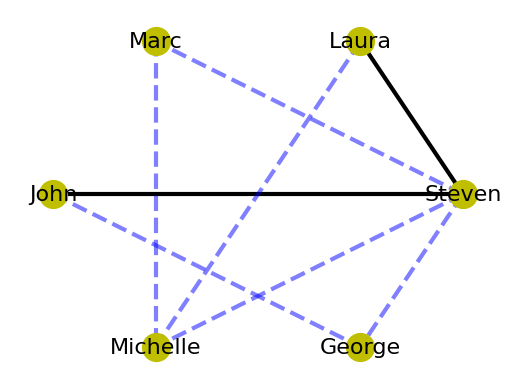

In [ ]:
# Show info and visualize (Fixed)
print(f"Number of nodes: {G_weighted.number_of_nodes()}")
print(f"Number of edges: {G_weighted.number_of_edges()}")

# Do these instead of just nx.draw_networkx(G_weighted) to visualize the weights
# Define two lists of edge to be applied different styles depending on weight
elarge = [(u, v) for (u, v, d) in G_weighted.edges(data=True) if d['weight'] > 8]
esmall = [(u, v) for (u, v, d) in G_weighted.edges(data=True) if d['weight'] <= 8]

pos = nx.circular_layout(G_weighted)  # positions for all nodes

# nodes
nx.draw_networkx_nodes(G_weighted, pos, node_size=400, node_color='y')
# edges
nx.draw_networkx_edges(G_weighted, pos, edgelist=elarge, width=3)
nx.draw_networkx_edges(G_weighted, pos, edgelist=esmall, width=3, alpha=0.5, edge_color='b', style='dashed')
# labels
nx.draw_networkx_labels(G_weighted, pos, font_size=16, font_family='sans-serif')

plt.axis('off')
plt.show()

### Activity (1)

Define the following asymmetric (directed) network with weights.

- All the solid lines have a weight of 10 while all the dashed lines have a weight of 5.

- Name it as ```G_ex``` so that we can use it again below.

- Produce the visualization as shown.

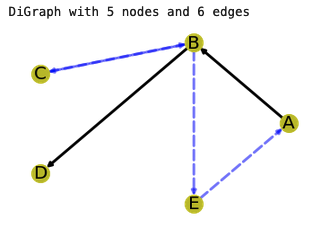

# Part 2: Analyzing the social network

Now that we have created the social network, we can analyze the connections among the nodes.

### Analysis 1: Degree

Degree of a node defines the number of edges attached to a node. ```NetworkX``` has the function ```degree``` which we can use to determine the degree of a node in the network.


#### Symmetric network

In our symmetric network ```G_symmetric```, Michelle has three connections. Therefore, her degree is 3. Similarly, the degress of Steven and George are 5 and 2 respectively.

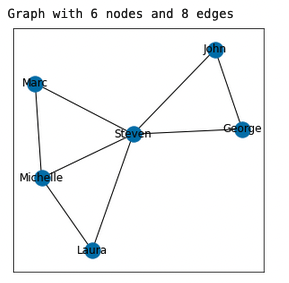

The degree can be calculated as follow:

In [ ]:
nx.degree(G_symmetric, 'Michelle')

3

In [ ]:
nx.degree(G_symmetric, 'Steven')

5

In [ ]:
nx.degree(G_symmetric, 'George')

2

#### Asymmetric network

For the asymmetric netowrk ```G_asymmetric```, we count the different directions as two edges. Therefore, node A has a degree of 4 instead of 3, as there is a double arrow between A and B. On the other hand, C only has a degree of 2.

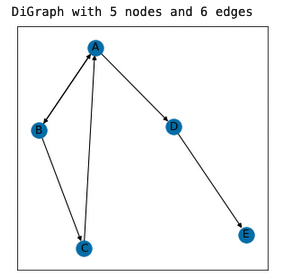

In [ ]:
nx.degree(G_asymmetric, 'A')

4

In [ ]:
nx.degree(G_asymmetric, 'C')

2

#### Weighted network

The weights in a weighted network do NOT affect the degree as we only count the number of edges regardless of their weights. In ```G_weighted```, for example,

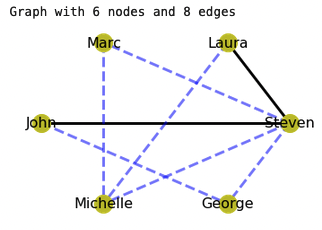

In [ ]:
nx.degree(G_weighted, 'Steven')

5

In [ ]:
nx.degree(G_weighted, 'John')

2

## Analysis 2: Clustering coefficient

It is observed that people who share connections in a social network tend to form associations. In other words, there is a tendency in a social network to form clusters.

This tendency is measured by the clustering coefficient. The local clustering coefficient is defined as the fraction of pairs of the node’s friends that are connected with each other.


#### Symmetric network

Again we use the symmetric employee network as an example, shown below again for convenience.

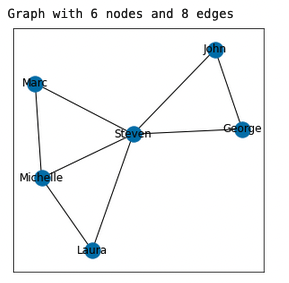

In this network, Michelle is connected to three people (Marc, Laura, and Steven). Out of these three people:
- Marc and Steven are connected.
- Steven and Laura are connected.
- Marc and Laura are NOT connected.

Therefore, out of the three possible connections among these three people, two of them are actually connected. The local clustering coefficient of Michelle is 2/3 = 0.67.

Let's also consider Laura. Laura is connected to two people (Steven and Michelle). There is only one possible connection between these two people and they are actually connected. Therefore, the local clustering coefficient of Laura is 1/1 = 1.

To calculate the local clustering coefficient, we use the ```nx.clustering(Graph, Node)``` function.



In [ ]:
nx.clustering(G_symmetric,'Michelle')

0.6666666666666666

In [ ]:
nx.clustering(G_symmetric,'Laura')

1.0

We can also calculate the average clustering coefficient (sum of all the local clustering coefficients divided by the number of nodes). Since the clustering coefficient of each node must fall into [0, 1], the average cluster coefficient is in [0, 1] as well.

In our case, can calculate the average clustering coefficient of our symmetric employee network as follows:

In [ ]:
nx.average_clustering(G_symmetric)

0.8277777777777778

#### Asymmetric network

The clustering coefficient for directed graphs is a bit more tricky as we need to consider the direction of the connections as well.

Consider ```G_asymmetric``` again below:

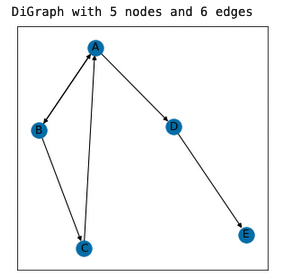

Node B has two neighbours (A and C). Since we count the two directions of connection as two edges, there are a total of two possible connections between A and C (A->C and C->A). Out of these two possible connections:
- A->C is connected.
- C->A is NOT connected.

Therefore, the local clustering coefficient of B is 1/2 = 0.5.

As another example, C has two neighbours (A and B). There are two possible connections between them (A->B and B->A). Out of these two possible connections:
- A->B is connected.
- B->A is connected.

Therefore, the local clustering coefficient of A is 2/2 = 1.


In [ ]:
nx.clustering(G_asymmetric, 'B')

0.5

In [ ]:
nx.clustering(G_asymmetric, 'C')

1.0

#### Weighted network

If it is a weighted network, the weight of the connections should be considered as well, and so it could be different from what we expect. We will skip this for simplicity.

Futher reference: https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.cluster.clustering.html#networkx.algorithms.cluster.clustering.

## Analysis 3: Network distance measures

We could also measure the distance between nodes in a network.

### Distance

We can determine the shortest path between two nodes and its length in ```NetworkX``` using ```nx.shortest_path(Graph, Node1, Node2)``` and ```nx.shortest_path_length(Graph, Node1, Node2)``` functions respectively.

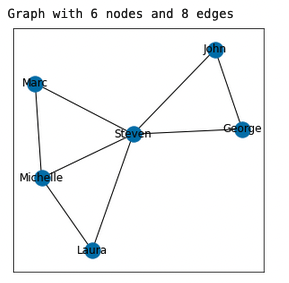

In [ ]:
nx.shortest_path(G_symmetric, 'Michelle', 'John')

['Michelle', 'Steven', 'John']

In [ ]:
nx.shortest_path_length(G_symmetric, 'Michelle', 'John')

2

Note: The path counts only the edge but not just any connection in general, as the direction of connection is also taken into account. In ```G_asymmetric```, for example, there is an edge A->D but no D->A. In fact, there is no way to go directly or indirectly from D to A in that network.

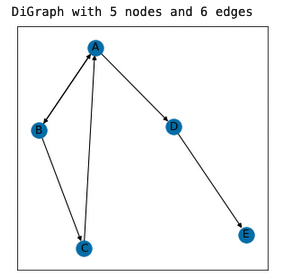

Therefore, the following will give an error.

In [ ]:
# This will give an error if uncommented
# nx.shortest_path(G_asymmetric, 'D', 'A')

NetworkXNoPath: No path between D and A.

### Breadth-first search

We can find the distance of a node from every other node in the network using breadth-first search algorithm, starting from that node. ```networkX``` provides the function ```bfs_tree``` to do it.

And so if you use ```M = nx.bfs_tree(G_symmetric, 'Michelle')``` and now draw this tree, we will get a network structure telling how we can reach other nodes of the network starting from Michelle .

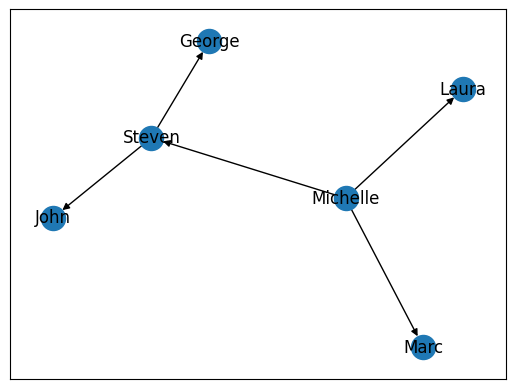

In [ ]:
M = nx.bfs_tree(G_symmetric, 'Michelle')
nx.draw_networkx(M)

Simiarly for Steven:

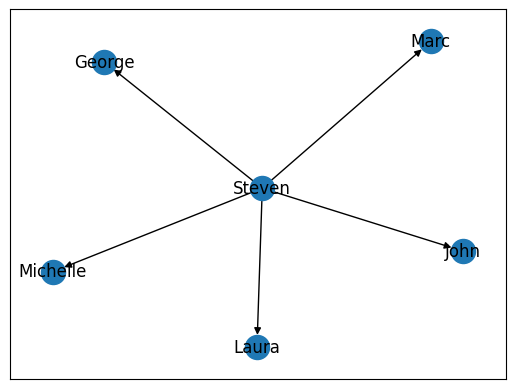

In [ ]:
S = nx.bfs_tree(G_symmetric, 'Steven')
nx.draw_networkx(S)

For asymmetric networks, the algorithm will only consider outgoing edges from the node. Therefore, in ```G_asymmetric```, the resulting graph will only show B and D but not C as neighbours of A. This is because in the original graph, there is no connection A->C, only C->A.

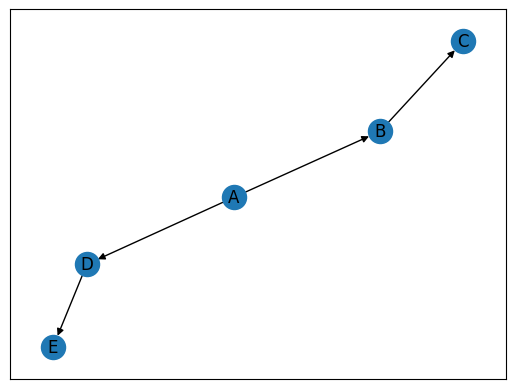

In [ ]:
S = nx.bfs_tree(G_asymmetric, 'A')
nx.draw_networkx(S)

### Eccentricity

Eccentricity of a node is defined as the largest distance between that node and all other nodes. In other words, we are asking the furthest distance from a node in the network.

It can be found using ```nx.eccentricity()``` function. In ```G_symmetric```, Michelle has an eccentricity of 2, and Steven has an eccentricity of 1 (because he is connected directly to every other node).

This is also apparent in the breadth-first search.

Eccentricity = 2


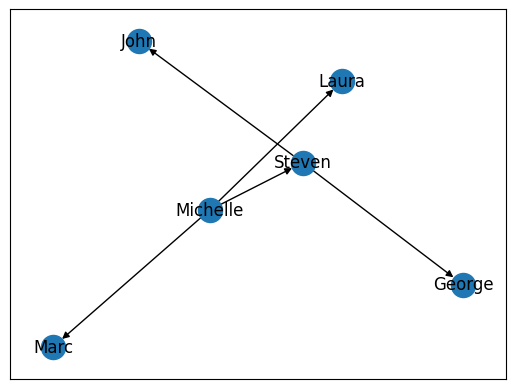

In [ ]:
print(f"Eccentricity = {nx.eccentricity(G_symmetric,'Michelle')}")
S = nx.bfs_tree(G_symmetric, 'Michelle')
nx.draw_networkx(S)

Eccentricity = 1


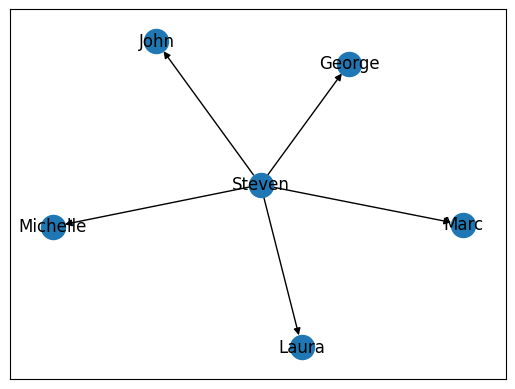

In [ ]:
print(f"Eccentricity = {nx.eccentricity(G_symmetric,'Steven')}")
S = nx.bfs_tree(G_symmetric, 'Steven')
nx.draw_networkx(S)

### Activity (2)

Consdier our ```G_ex``` again:



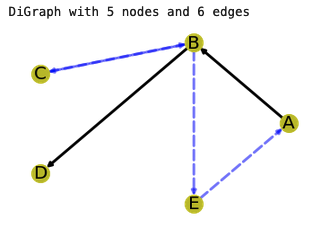

Write codes to show:

1. The degree of A
2. The clustering coefficient of A
3. The breadth-first search graph for A
4. The shortest path and path length between A and E
5. The eccentricity of A

In [ ]:
# Degree of A


In [ ]:
# Clustering coefficient of A


In [ ]:
# Breadth-first search


In [ ]:
# Shortest path from A to E


In [ ]:
# Shortest path length from A to E


In [ ]:
# Eccentricity of A


## Analysis 4: Centrality measures

Above we learned some of the network distance measures and they are useful in knowing how the information will spread through the network.

In this section, we will learn how to find the most important nodes (individuals) in the network. These parameters are called as centrality measures. Centrality Measures can help us in identifying popularity, most liked, and biggest influencers within the network.

In this part we consider the symmetric networks and ignore the asymmetric and weighted networks for simplicity.

### Degree centrality (Who has the most connections?)

The people most popular or more liked usually are the ones who have more friends (connections).

Degree centrality is a measure of the number of connections a particular node has in the network. It is defined as the degree of a node divided by n-1, where n is the number of nodes.

It is based on the fact that important nodes have many connections. ```NetworkX``` has the function ```degree_centrality()``` to calculate the degree centrality of all the nodes of a network.


In ```G_symmetric```:

- Steven is connected to all the other 5 nodes. His degree centrality is 5/5 = 1.
- Laura is connected to 2 nodes out of 5 possible nodes. Her degree centrality is 2/5 = 0.4. Same for Marc, John, and George.
- Michelle is connected to 3 nodes out of 5 possible nodes. Her degree centrality is 3/5 = 0.6.

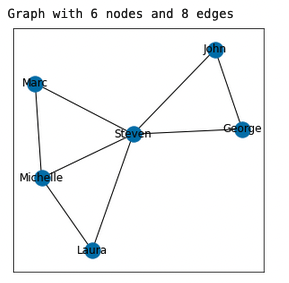

In [ ]:
nx.degree_centrality(G_symmetric)

{'Steven': 1.0,
 'Laura': 0.4,
 'Marc': 0.4,
 'John': 0.4,
 'Michelle': 0.6000000000000001,
 'George': 0.4}

### Eigenvector centrality (Who connects to most other important nodes?)

It is not just how many individuals one is connected too, but the type of people one is connected with that can decide the importance of a node.

Eigenvector centrality is a measure of how important a node is by accounting for the fact of how well it is connected to other important nodes. It definition is given in https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.eigenvector_centrality.html#networkx.algorithms.centrality.eigenvector_centrality. The larger the value of eigenvector centrality of a node, the more important the node.

We can use the ```eigenvector_centrality()``` function of NetworkX to calculate eigenvector centrality of all the nodes in a network.

**Google’s PageRank algorithm is a variant of Eigenvector centrality algorithm.**

Without much surprise, in ```G_symmetric```, Steven has the highest eigenvector centrality, while John and George have the lowest.

In [ ]:
nx.eigenvector_centrality(G_symmetric)

{'Steven': 0.6006686104947807,
 'Laura': 0.35456776607980744,
 'Marc': 0.35456776607980744,
 'John': 0.3084459243342467,
 'Michelle': 0.4443904166426226,
 'George': 0.3084459243342467}

### Closeness centrality (Who is closest to all others?)

Closeness Centrality is a measure where each node’s importance is determined by closeness to all other nodes. A larger value of closeness centrality means that the node is closest to all the other nodes on average.

The definition can be found at https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.closeness_centrality.html#networkx.algorithms.centrality.closeness_centrality.

In [ ]:
nx.closeness_centrality(G_symmetric)

{'Steven': 1.0,
 'Laura': 0.625,
 'Marc': 0.625,
 'John': 0.625,
 'Michelle': 0.7142857142857143,
 'George': 0.625}

### Betweenness centrality (Who is at the point of strategic importance?)

Betweenness centrality is the centrality of control. It represents the frequency at which a node occurs on the shortest paths that connected pair of nodes. It quantifies how many times a particular node comes in the shortest chosen path between two other nodes.

**The nodes with high betweenness centrality play a significant role in the communication/information flow within the network.**

The nodes with high betweenness centrality can have a strategic control and influence on others. **An individual at such a strategic position can influence the whole group, by either withholding or coloring the information in transmission.**

```Networkx``` has the function ```betweenness_centrality()``` to measure it for the network. It has options to select if we want betweenness values to be normalized or not, weights to be included in centrality calculation or not, and to include the endpoints in the shortest path counts or not.

1. The Formula

The betweenness centrality $C_B(v)$ of a node $v$ is calculated as:$$C_B(v) = \sum \frac{\sigma_{st}(v)}{\sigma_{st}}$$


 $\sigma_{st}$: The total number of shortest paths from source node $s$ to target node $t$.

$\sigma_{st}(v)$: The number of those shortest paths that pass through node $v$.2.


The Step-by-Step Breakdown for StevenYour network G_symmetric contains 6 nodes in total: Steven, Laura, Marc, John, Michelle, and George.

There are a total of $\frac{N(N-1)}{2} = \frac{6 \times 5}{2} = 15$ unique pairs of nodes in the network. We need to check how many of those 15 pairs require a shortest path that goes through Steven.

Let's group the other 5 nodes into two "sides" of the network connected primarily through Steven:

Group 1: Laura, Marc, Michelle (who are tightly interconnected with each other and Steven).

Group 2: George, John (who are connected to each other, and George connects to Steven).

---

A. Paths between Group 1 and Group 2 (Cross-network
traffic)

Every single shortest path between someone in Group 1 (e.g., Laura) and someone in Group 2 (e.g., John or George) must pass through Steven:

Laura $\leftrightarrow$ John (Path: Laura – Steven – John) $\rightarrow$ Passes through Steven

Laura $\leftrightarrow$ George (Path: Laura – Steven – George) $\rightarrow$ Passes through Steven

Marc $\leftrightarrow$ John (Path: Marc – Steven – John) $\rightarrow$ Passes through Steven

Marc $\leftrightarrow$ George (Path: Marc – Steven – George) $\rightarrow$ Passes through Steven

Michelle $\leftrightarrow$ John (Path: Michelle – Steven – John) $\rightarrow$ Passes through Steven

Michelle $\leftrightarrow$ George (Path: Michelle – Steven – George) $\rightarrow$ Passes through Steven

That gives $3 \times 2 = 6$ pairs whose absolute only shortest path goes through Steven ($\sigma_{st}(v) / \sigma_{st} = 1 / 1 = 1$ for each).

---
B. Paths entirely within Group 1 (Laura, Marc, Michelle)

We want to find all shortest paths between Laura ($s$) and Marc ($t$), and see how many of them pass through Steven ($v$).

Path 1 (via Michelle):Laura $\rightarrow$ Michelle $\rightarrow$ Marc

Length: 2 steps
Does it pass through Steven? No.

Path 2 (via Steven):Laura $\rightarrow$ Steven $\rightarrow$ Marc

Length: 2 steps

Does it pass through Steven? Yes.

Applying the Betweenness Formula  

The formula for betweenness centrality counts the fraction of shortest paths passing through a node:
$$\frac{\sigma_{st}(v)}{\sigma_{st}}$$

$\sigma_{st}$ (Total shortest paths between Laura and Marc): There are 2 equally valid shortest paths of length 2.

$\sigma_{st}(\text{Steven})$ (Shortest paths passing through Steven): Only 1 of those paths goes through Steven.

Therefore, for the pair Laura and Marc, Steven gets a credit of:

$$\frac{1}{2} = \mathbf{0.5}$$

---
C. Paths entirely within Group 2 (John, George)George $\leftrightarrow$ John: Direct edge (distance = 1), doesn't use Steven.

---
3. Summing It Up (The Final Calculation)NetworkX normalizes betweenness centrality by dividing the raw score by the maximum possible number of pairs that could pass through a node, which is $\frac{(N-1)(N-2)}{2}$ for an undirected graph (where $N = 6$):

$$\text{Maximum possible pairs} = \frac{(6-1)(6-2)}{2} = \frac{5 \times 4}{2} = 10$$

Steven lies on the shortest paths for 6.5 of those normalized pairs (accounting for fractional alternative paths within groups):

$$C_B(\text{Steven}) = \frac{6.5}{10} = \mathbf{0.65}$$


This exceptionally high score confirms that Steven is the absolute central bottleneck of the office network—if Steven were removed, communication between the George/John cluster and the Laura/Marc/Michelle cluster would be completely severed.

In [ ]:
nx.betweenness_centrality(G_symmetric)

{'Steven': 0.65,
 'Laura': 0.0,
 'Marc': 0.0,
 'John': 0.0,
 'Michelle': 0.05,
 'George': 0.0}

Again, it is not surprising that Steven has the highest betweenness centrality.

# Part 3: Facebook case study (Optional)

## Facebook friends list data

Now we look at a real dataset of Facebook connection data.

This dataset consists of ‘circles’ (or ‘friends lists’) from Facebook collected from survey participants using a dedicated Facebook app. The data has been anonymized by replacing the Facebook-internal ids for each user with a new value.

Source: J. McAuley and J. Leskovec. Learning to Discover Social Circles in Ego Networks. NIPS, 2012

I have downloaded the data and put into my Github account. You can read the data as follows:

In [1]:
import pandas as pd
df = pd.read_csv('https://raw.githubusercontent.com/drhycheung/webi/main/facebook_combined.txt')
df.info()

HTTPError: HTTP Error 404: Not Found

Each row of data consists of pairs of nodes, which indicates that the two nodes are connected in a symmetric network. For example, 0 2 means that users 0 and 2 are friends, while 0 3 means that users 0 and 3 are friends, and so on.

In [ ]:
df

We can create and visualize the graph as follows:

(But it will take quite some time due to the huge amount of data. If you just want to see the resulting graph then you may not want to run it.)

In [ ]:
import urllib
fin = urllib.request.urlopen('https://raw.githubusercontent.com/drhycheung/webi/main/facebook_combined.txt')

G_fb = nx.read_edgelist(fin, create_using = nx.Graph(), nodetype=int)
print(nx.info(G_fb))
plt.figure(figsize=(20,20))
nx.draw_networkx(G_fb);

fin.close()

We can also visualize the network such that the node color varies with Degree and node size with Betweenness Centrality. The code to do this is:

In [ ]:
pos = nx.spring_layout(G_fb)
betCent = nx.betweenness_centrality(G_fb, normalized=True, endpoints=True)
node_color = [20000.0 * G_fb.degree(v) for v in G_fb]
node_size =  [v * 10000 for v in betCent.values()]
plt.figure(figsize=(20,20))
nx.draw_networkx(G_fb, pos=pos, with_labels=False,
                 node_color=node_color,
                 node_size=node_size )
plt.axis('off');

There are some particularly large nodes, which means that they have large betweenness centrality (i.e., they are at the point of strategic importance).

## Centrality measures of Facebook data

Let's compare the top-10s in the various measures of centrality:

In [ ]:
# Show top-10s in degree centrality (Who has the most connections?)
degCent = nx.degree_centrality(G_fb)
degCent_sorted = dict(sorted(degCent.items(), key=lambda item: item[1], reverse=True))
list(degCent_sorted.items())[:10] # Show the top 10 with centrality measure

In [ ]:
# Show top-10s in betweenness centrality (Who is at the point of strategic importance?)
betCent = nx.betweenness_centrality(G_fb, normalized=True, endpoints=True) # Can skip if already done above
betCent_sorted = dict(sorted(betCent.items(), key=lambda item: item[1], reverse=True))
list(betCent_sorted.items())[:10] # Show the top 10 with centrality measure

It is natural that nodes that are more connected (i.e., with large degree centrality) also lie on shortest paths between other nodes (i.e., with large betweenness centrality). The nodes 107, 1684, 3437, 1912, 0 are all in both lists.

In [ ]:
# Show top-10s in eigenvector centrality (Who is the most important?)
eigCent = nx.eigenvector_centrality(G_fb)
eigCent_sorted = dict(sorted(eigCent.items(), key=lambda item: item[1], reverse=True))

list(eigCent_sorted.items())[:10] # Show the top 10 with centrality measure

We can also see that node 1912 is common among the three measures considered. This node has a lot of connections, is at the point of stragegic importance, and also connect to most other important nodes.

Last but not least, node 107 is found to be closest to all other notes. Node 1684 is also on list.

In [ ]:
# Show top-10s in closeness centrality (Who is closest to all others?)
cloCent = nx.closeness_centrality(G_fb)
cloCent_sorted = dict(sorted(cloCent.items(), key=lambda item: item[1], reverse=True))

list(cloCent_sorted.items())[:10] # Show the top 10 with centrality measure